<a href="https://colab.research.google.com/github/harleenk2295-cpu/c-practice/blob/main/confusion_matrix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SVC 



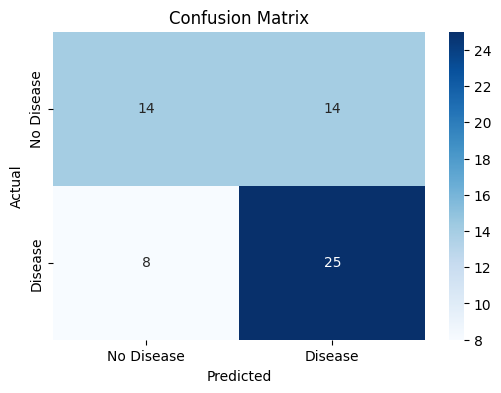

KNeighborsClassifier 



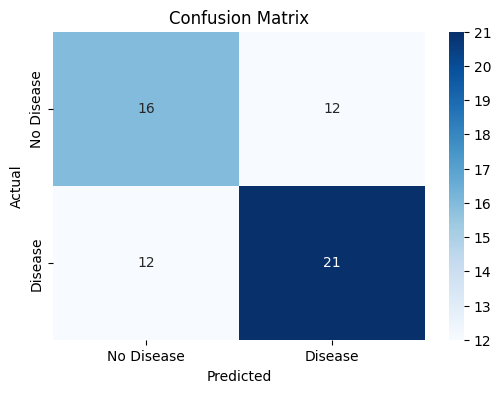

RandomForestClassifier 



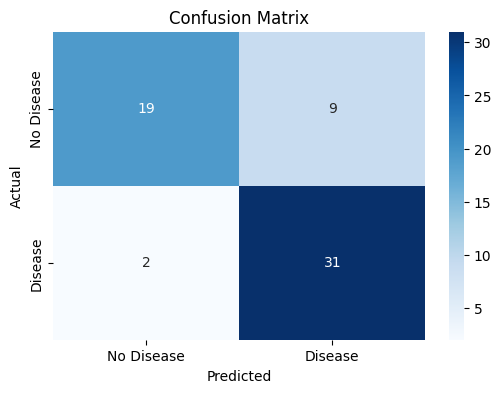

LogisticRegression 



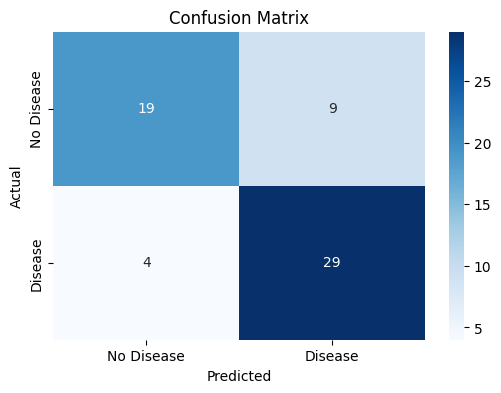

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,roc_curve,auc
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

df=pd.read_csv('/content/archive (3).zip')
df=df.drop_duplicates()
x=df.drop('target',axis=1)
y=df['target']

models={
    'SVC':SVC(probability=True),
    'KNeighborsClassifier':KNeighborsClassifier(),
    'RandomForestClassifier':RandomForestClassifier(),
    'LogisticRegression':LogisticRegression(max_iter=1000)
}
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
acc={}
pre={}
rec={}
for name,model in models.items():
    model.fit(xtrain,ytrain)
    pred=model.predict(xtest)
    print(name,'\n')
    cm = confusion_matrix(ytest,pred)
# Plot confusion matrix
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Disease', 'Disease'],
yticklabels=['No Disease', 'Disease'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

In [2]:
for name,model in models.items():
    model.fit(xtrain,ytrain)
    pred=model.predict(xtest)
    acc[name]=accuracy_score(ytest,pred)
    pre[name]=precision_score(ytest,pred)
    rec[name]=recall_score(ytest,pred)
print('accuracy:\n')
for name,ac in acc.items():
    print(name,ac*100)
print('\nprecision:\n')
for name,ac in pre.items():
    print(name,ac*100)
print('\nrecall:\n')
for name,ac in rec.items():
    print(name,ac*100)

accuracy:

SVC 63.934426229508205
KNeighborsClassifier 60.65573770491803
RandomForestClassifier 81.9672131147541
LogisticRegression 78.68852459016394

precision:

SVC 64.1025641025641
KNeighborsClassifier 63.63636363636363
RandomForestClassifier 77.5
LogisticRegression 76.31578947368422

recall:

SVC 75.75757575757575
KNeighborsClassifier 63.63636363636363
RandomForestClassifier 93.93939393939394
LogisticRegression 87.87878787878788


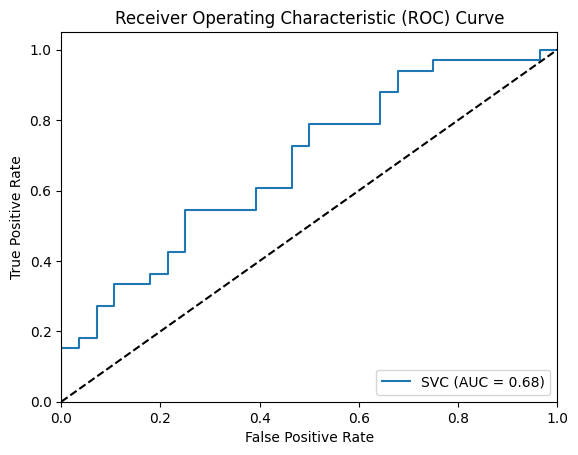

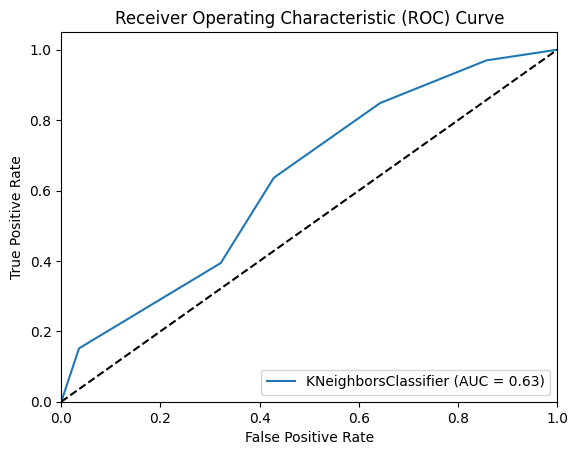

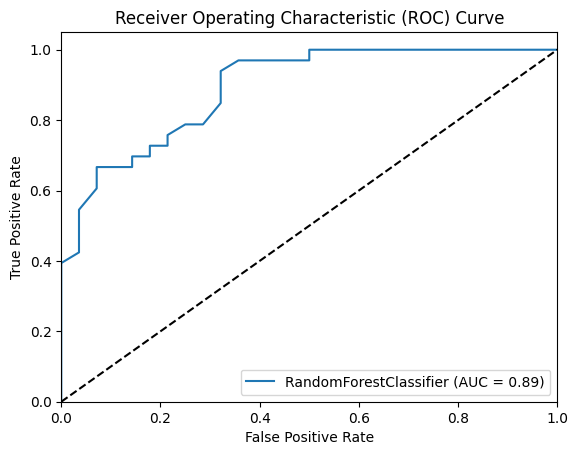

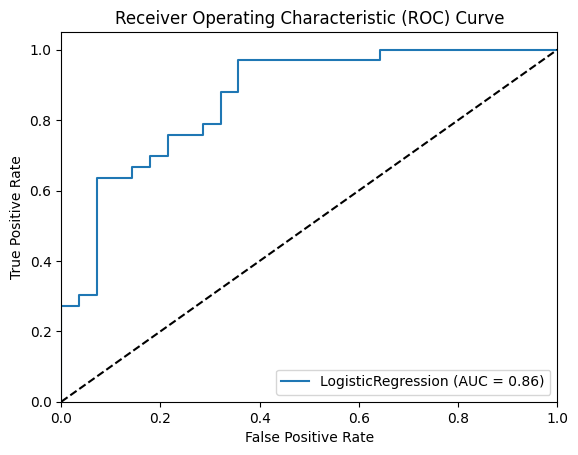

In [3]:
for name,model in models.items():
    y_probs = model.predict_proba(xtest)[:, 1]  # Get probabilities for the positive class
    fpr, tpr, _ = roc_curve(ytest, y_probs)
    roc_auc = auc(fpr, tpr)

    # Plot ROC curve
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.2f})')

# Finalize ROC plot
    plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve')
    plt.legend(loc='lower right')
    plt.show()

SVC 



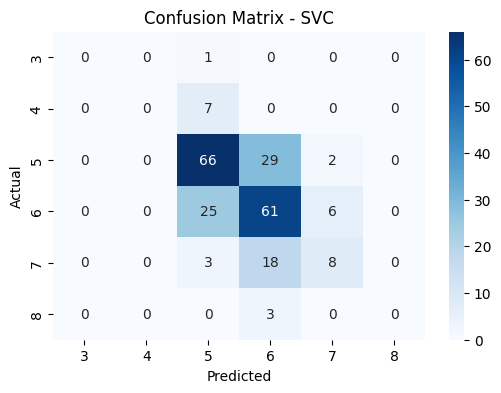

KNeighborsClassifier 



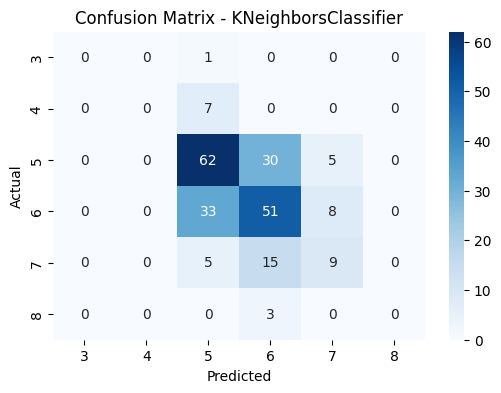

RandomForestClassifier 



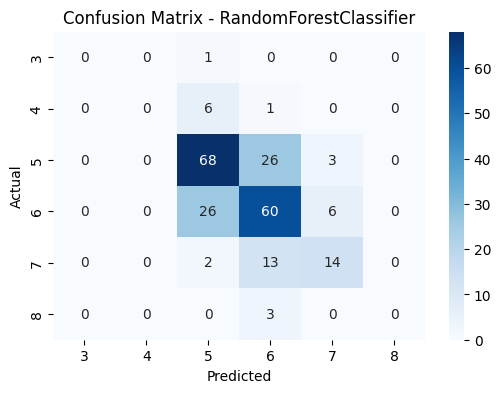

LogisticRegression 



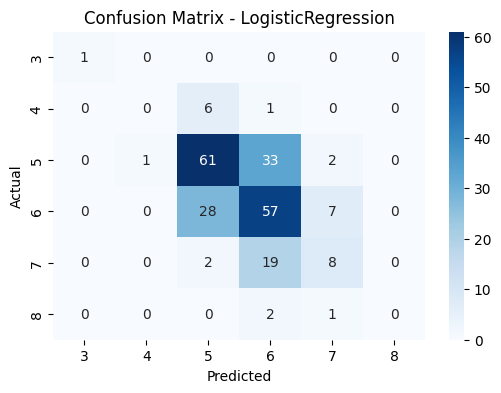

In [17]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

df = pd.read_csv('/content/archive (13).zip')
df = df.drop_duplicates()
df = df.sort_values(by=['quality'], ascending=True)

x = df.drop('quality', axis=1)
y = df['quality']

models = {
    'SVC': make_pipeline(StandardScaler(), SVC(probability=True)),
    'KNeighborsClassifier': make_pipeline(StandardScaler(), KNeighborsClassifier()),
    'RandomForestClassifier': RandomForestClassifier(random_state=42),
    'LogisticRegression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=10000)
    )
}

xtrain, xtest, ytrain, ytest = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

acc = {}
pre = {}
rec = {}

for name, model in models.items():
    model.fit(xtrain, ytrain)
    pred = model.predict(xtest)

    acc[name] = accuracy_score(ytest, pred)
    pre[name] = precision_score(
        ytest, pred, average='weighted', zero_division=0
    )
    rec[name] = recall_score(
        ytest, pred, average='weighted', zero_division=0
    )

    print(name, '\n')

    cm = confusion_matrix(ytest, pred, labels=sorted(y.unique()))

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=sorted(y.unique()),
        yticklabels=sorted(y.unique())
    )
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title(f'Confusion Matrix - {name}')
    plt.show()



In [15]:

for name, model in models.items():
    model.fit(xtrain, ytrain)
    pred = model.predict(xtest)

    acc[name] = accuracy_score(ytest, pred)
    pre[name] = precision_score(ytest, pred, average='weighted', zero_division=0)
    rec[name] = recall_score(ytest, pred, average='weighted', zero_division=0)

print('Accuracy:\n')
for name, ac in acc.items():
    print(name, ac * 100)

print('\nPrecision:\n')
for name, ac in pre.items():
    print(name, ac * 100)

print('\nRecall:\n')
for name, ac in rec.items():
    print(name, ac * 100)

Accuracy:

SVC 67.24890829694323
KNeighborsClassifier 57.64192139737992
RandomForestClassifier 70.3056768558952
LogisticRegression 62.882096069869

Precision:

SVC 64.24119750307668
KNeighborsClassifier 54.85765014773125
RandomForestClassifier 66.86659974287666
LogisticRegression 59.23575092934451

Recall:

SVC 67.24890829694323
KNeighborsClassifier 57.64192139737992
RandomForestClassifier 70.3056768558952
LogisticRegression 62.882096069869


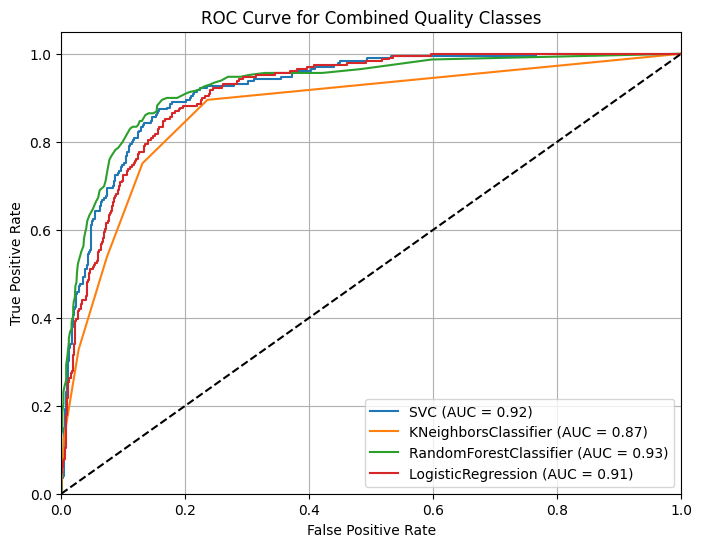

In [14]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Load the dataset
df = pd.read_csv('/content/archive (13).zip')
df = df.drop_duplicates()

# Define features and target
x = df.drop('quality', axis=1)
y = df['quality']

# Select quality classes 3, 4, 5, 6, 7, 8
y = y[y.isin([3, 4, 5, 6, 7, 8])]
x = x.loc[y.index]

# Get available classes
classes = np.unique(y)

# Split the data
xtrain, xtest, ytrain, ytest = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Binarize test labels for ROC calculation
ytest_bin = label_binarize(ytest, classes=classes)

# Define models
models = {
    'SVC': make_pipeline(
        StandardScaler(),
        SVC(probability=True, random_state=42)
    ),
    'KNeighborsClassifier': make_pipeline(
        StandardScaler(),
        KNeighborsClassifier()
    ),
    'RandomForestClassifier': RandomForestClassifier(
        random_state=42
    ),
    'LogisticRegression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )
}

# Plot ROC curves
plt.figure(figsize=(8, 6))

for name, model in models.items():
    # Train the model
    model.fit(xtrain, ytrain)

    # Predict class probabilities
    y_probs = model.predict_proba(xtest)

    # Calculate combined multiclass ROC curve
    fpr, tpr, _ = roc_curve(
        ytest_bin.ravel(),
        y_probs.ravel()
    )

    roc_auc = auc(fpr, tpr)

    # Plot ROC curve
    plt.plot(
        fpr, tpr,
        label=f'{name} (AUC = {roc_auc:.2f})'
    )

# Random chance line
plt.plot([0, 1], [0, 1], 'k--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Combined Quality Classes')
plt.legend(loc='lower right')
plt.grid()
plt.show()
